In [17]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [18]:
# Імпортуємо датасет:
column_names = [
    'Sex',
    'Length',
    'Diameter',
    'Height',
    'Whole_weight',
    'Shucked_weight',
    'Viscera_weight',
    'Shell_weight',
    'Rings',
]
df1 = pd.read_csv('abalone.data', header=None, names=column_names)
print(df1.head())
print(df1.info())

  Sex  Length  Diameter  Height  Whole_weight  Shucked_weight  Viscera_weight  \
0   M   0.455     0.365   0.095        0.5140          0.2245          0.1010   
1   M   0.350     0.265   0.090        0.2255          0.0995          0.0485   
2   F   0.530     0.420   0.135        0.6770          0.2565          0.1415   
3   M   0.440     0.365   0.125        0.5160          0.2155          0.1140   
4   I   0.330     0.255   0.080        0.2050          0.0895          0.0395   

   Shell_weight  Rings  
0         0.150     15  
1         0.070      7  
2         0.210      9  
3         0.155     10  
4         0.055      7  
<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float6

In [19]:
#2 Перевіряємо кількість пропусків, дуплікатів та типи данних
missing_values = df1.isnull().sum()
print(missing_values)

duplicates_count = df1.duplicated().sum()
print(duplicates_count)
print(df1.dtypes)
print(df1.columns.tolist())

Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64
0
Sex                   str
Length            float64
Diameter          float64
Height            float64
Whole_weight      float64
Shucked_weight    float64
Viscera_weight    float64
Shell_weight      float64
Rings               int64
dtype: object
['Sex', 'Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Rings']


In [20]:
#Додаємо фічу яка переносит значення з колонки 'Sex' у числа та зберігає їх в окремих колонка 'Sex_I', 'Sex_M', 'Sex_F'
if 'Sex' in df1.columns:
    df1 = pd.get_dummies(df1, columns=['Sex'], drop_first=True, dtype=int)

In [21]:
#Розбиваємо 'Rings' на 3 класи ( 0 — молоді, 1 — середні, 2 — старі)
bins = [0, 8, 11, max(df1['Rings'])]
labels = [0, 1, 2]
df1['Ring_Class'] = pd.cut(df1['Rings'], bins=bins, labels=labels)

X = df1.drop(columns=['Rings', 'Ring_Class'])
y = df1['Ring_Class'].astype(int)

In [22]:
#поділ датасету на тренувальну, валідаційну та тестову частини
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

In [23]:
#Масштабування фіч

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [24]:
#Тренування моделі з дефолтними параметрами
base_model = KNeighborsClassifier(n_neighbors=5)
base_model.fit(X_train_scaled, y_train)

y_val_pred = base_model.predict(X_val_scaled)
print(f'Базова модель Accuracy (val): {accuracy_score(y_val, y_val_pred):.4f}')

Базова модель Accuracy (val): 0.6396


In [25]:
#Підбір гіперпараметрів
knn_clf = KNeighborsClassifier()

param_grid = {
    'n_neighbors': [5, 10, 15, 20, 30],
    'metric': ['euclidean', 'manhattan'],
    'weights': ['uniform', 'distance'],
}

grid_search = GridSearchCV(
    estimator=knn_clf, param_grid=param_grid, cv=5, scoring='accuracy'
)
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_
print(f'Найкращі параметри: {grid_search.best_params_}')

Найкращі параметри: {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'distance'}


In [26]:
#результати після підбору гіперпараметрів
y_test_pred = best_model.predict(X_test_scaled)

test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='weighted')

print(f'Фінальна точність Accuracy (test): {test_acc:.4f}')
print(f'Фінальний зважений F1-score (test): {test_f1:.4f}')


Фінальна точність Accuracy (test): 0.6571
Фінальний зважений F1-score (test): 0.6532


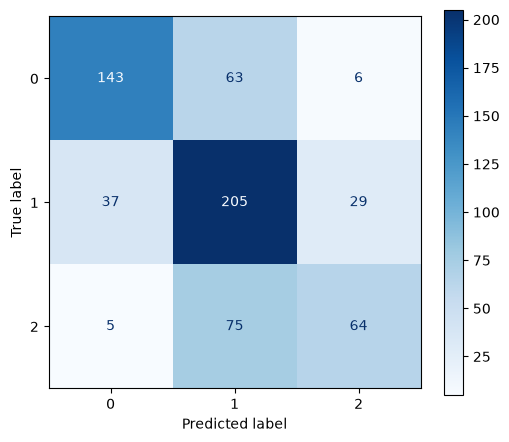

In [27]:
#Побудуємо лінійну модель для порівняння
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, cmap='Blues', ax=plt.gca()
)
plt.grid(False)
plt.show()

In [13]:
#Матриця показує, що модель непогано справляється з класами `0` і `1`, але часто плутає клас `2` (старих) із класом `1` (середніх), оскільки вони #мають схожі фізичні параметри раковини. Саме тому загальна точність зупинилася на позначці `0.6571`.
